# 2. Credit Card Fraud Detection
## Imports and Efficient Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn modules
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_recall_curve, auc, classification_report, 
                             confusion_matrix, average_precision_score)
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Set styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load Data (specifying dtypes to save memory)
print("Loading data...")
dtypes = {'Time': np.float32, 'Amount': np.float32, 'Class': np.int8}
# V1-V28 will be inferred as float32
df = pd.read_csv('../data/credit card fraud detection/creditcard.csv', dtype=dtypes)
print(f"Dataset loaded successfully. Shape: {df.shape}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Loading data...
Dataset loaded successfully. Shape: (284807, 31)
Memory usage: 63.29 MB


## EDA

--- Class Distribution ---
Normal (0): 284315 (99.827%)
Fraud (1):  492 (0.173%)


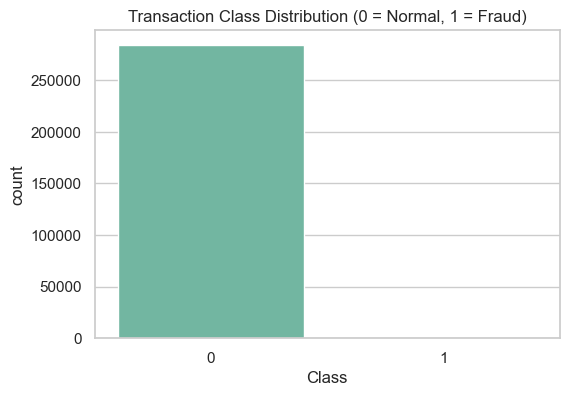

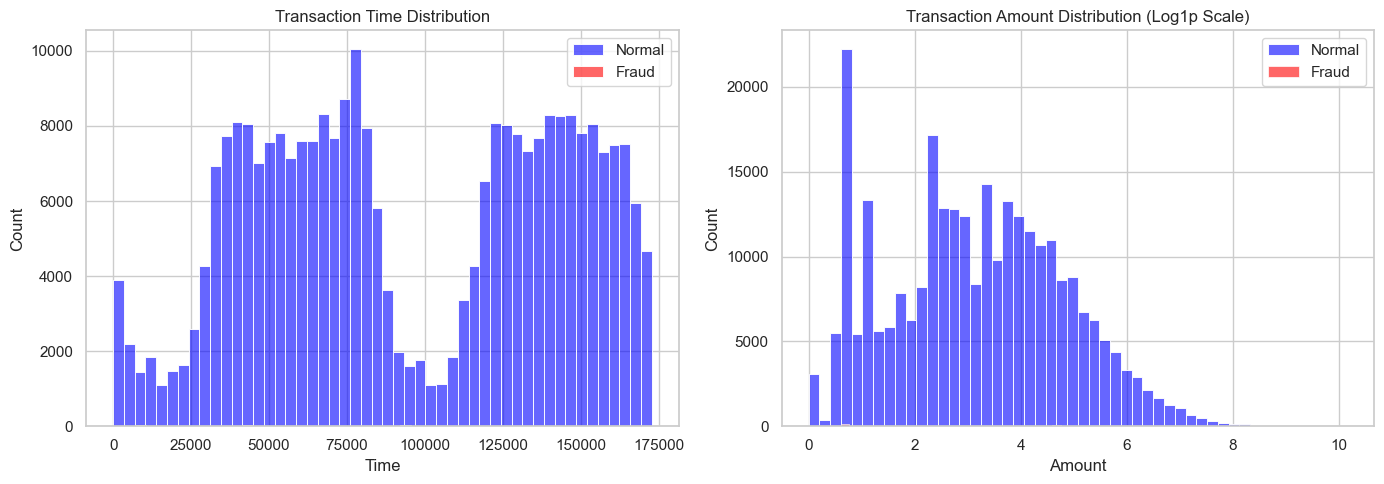


--- Amount Statistics ---
          count        mean         std  min   25%    50%         75%  \
Class                                                                   
0      284315.0   88.291016  250.105103  0.0  5.65  22.00   77.050003   
1         492.0  122.211319  256.683289  0.0  1.00   9.25  105.889999   

                max  
Class                
0      25691.160156  
1       2125.870117  


In [3]:
# 1. Class Distribution (The core challenge)
class_counts = df['Class'].value_counts()
print("--- Class Distribution ---")
print(f"Normal (0): {class_counts[0]} ({class_counts[0]/len(df)*100:.3f}%)")
print(f"Fraud (1):  {class_counts[1]} ({class_counts[1]/len(df)*100:.3f}%)")

# 2. Visualize Class Imbalance
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df, palette='Set2')
plt.title('Transaction Class Distribution (0 = Normal, 1 = Fraud)')
plt.show()

# 3. Analyze 'Time' and 'Amount' (The only non-PCA features)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Time distribution by class
sns.histplot(df[df['Class']==0]['Time'], bins=50, ax=axes[0], color='blue', label='Normal', alpha=0.6)
sns.histplot(df[df['Class']==1]['Time'], bins=50, ax=axes[0], color='red', label='Fraud', alpha=0.6)
axes[0].set_title('Transaction Time Distribution')
axes[0].legend()

# Amount distribution by class (Log scale for visibility)
sns.histplot(np.log1p(df[df['Class']==0]['Amount']), bins=50, ax=axes[1], color='blue', label='Normal', alpha=0.6)
sns.histplot(np.log1p(df[df['Class']==1]['Amount']), bins=50, ax=axes[1], color='red', label='Fraud', alpha=0.6)
axes[1].set_title('Transaction Amount Distribution (Log1p Scale)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("\n--- Amount Statistics ---")
print(df.groupby('Class')['Amount'].describe())

## Data Preparation & Justification

In [4]:
# JUSTIFICATION:
# 1. Features V1-V28 are already scaled via PCA (mean=0, variance=1). We leave them untouched.
# 2. 'Time' and 'Amount' are on completely different scales and 'Amount' has extreme outliers.
# 3. We apply RobustScaler to 'Time' and 'Amount' because it uses median and IQR, 
#    making it resilient to the extreme outliers present in the 'Amount' feature.
# 4. We perform a stratified train-test split to ensure the 0.172% fraud rate is 
#    preserved in both sets, which is critical for evaluating ranking performance.

# Apply Robust Scaling to Time and Amount
scaler = RobustScaler()
df[['Time', 'Amount']] = scaler.fit_transform(df[['Time', 'Amount']])

# Define features and target
X = df.drop('Class', axis=1)
y = df['Class']

# Stratified split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}, Fraud rate: {y_train.mean()*100:.3f}%")
print(f"Test set shape: {X_test.shape}, Fraud rate: {y_test.mean()*100:.3f}%")

Training set shape: (227845, 30), Fraud rate: 0.173%
Test set shape: (56962, 30), Fraud rate: 0.172%


## Statistical Outlier Baseline

In [5]:
# JUSTIFICATION: Before applying ML, we establish a naive statistical baseline.
# A simple rule: flag transactions where the 'Amount' is a statistical outlier 
# (e.g., Z-score > 3 or > 99th percentile). This represents a traditional rule-based system.

# Calculate Z-score for Amount in the test set
test_amount = df.loc[X_test.index, 'Amount'] # Note: X_test retains original indices
mean_amount = test_amount.mean()
std_amount = test_amount.std()
z_scores = np.abs((test_amount - mean_amount) / std_amount)

# Baseline prediction: 1 if Z-score > 3, else 0
y_pred_baseline = (z_scores > 3).astype(int)

print("--- Statistical Outlier Baseline (Z-score > 3 on Amount) ---")
print(f"Total flagged: {y_pred_baseline.sum()}")
print(f"Actual frauds in test set: {y_test.sum()}")

# Calculate Recall@K for baseline (How many actual frauds did we catch in our flagged set?)
true_positives_baseline = ((y_pred_baseline == 1) & (y_test == 1)).sum()
recall_at_k_baseline = true_positives_baseline / y_test.sum() if y_test.sum() > 0 else 0
print(f"Recall of flagged transactions: {recall_at_k_baseline*100:.2f}%")

--- Statistical Outlier Baseline (Z-score > 3 on Amount) ---
Total flagged: 882
Actual frauds in test set: 98
Recall of flagged transactions: 1.02%


## Cluster-Based / Unsupervised Anomaly Detection Approach

In [6]:
# JUSTIFICATION: Isolation Forest is chosen for the cluster-based/anomaly approach.
# It isolates observations by randomly selecting a feature and then randomly selecting 
# a split value. Anomalies are "easier" to isolate (require fewer splits). 
# It is highly efficient, handles high-dimensional data well, and does not require 
# labeled data, making it robust to label noise.

print("Training Isolation Forest...")
# contamination is set to the approximate fraud rate (0.00172)
iso_forest = IsolationForest(n_estimators=100, contamination=0.00172, random_state=42, n_jobs=-1)
iso_forest.fit(X_train)

# Get anomaly scores (more negative = more anomalous)
# We convert to a probability-like score for ranking: higher = more anomalous
iso_scores = -iso_forest.score_samples(X_test)
y_pred_iso = iso_forest.predict(X_test)
y_pred_iso = np.where(y_pred_iso == -1, 1, 0) # Convert -1 (anomaly) to 1, 1 (normal) to 0

print("Isolation Forest Classification Report:")
print(classification_report(y_test, y_pred_iso, zero_division=0))

Training Isolation Forest...
Isolation Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.31      0.34      0.32        98

    accuracy                           1.00     56962
   macro avg       0.65      0.67      0.66     56962
weighted avg       1.00      1.00      1.00     56962



## Classification Based Approach

In [7]:
# JUSTIFICATION: Random Forest is chosen for the supervised classification approach.
# It handles non-linear relationships well, is robust to overfitting, and provides 
# feature importance. To handle the 0.172% imbalance, we use class weighting 
# (scale_pos_weight or class_weight='balanced') to penalize missing frauds heavily.

print("Training Random Forest Classifier...")
# Calculate scale_pos_weight: (number of negative samples) / (number of positive samples)
weight = (y_train == 0).sum() / (y_train == 1).sum()

rf_clf = RandomForestClassifier(
    n_estimators=100, 
    class_weight={0: 1, 1: weight}, # Heavily weight the minority class
    random_state=42, 
    n_jobs=-1,
    max_depth=10 # Prevent overfitting to noise
)
rf_clf.fit(X_train, y_train)

# Get predicted probabilities for ranking (probability of class 1)
rf_probs = rf_clf.predict_proba(X_test)[:, 1]
y_pred_rf = rf_clf.predict(X_test)

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Training Random Forest Classifier...
Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.82      0.82        98

    accuracy                           1.00     56962
   macro avg       0.91      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962



## Evaluate Ranking Performance

--- Ranking Evaluation ---
Isolation Forest PR-AUC: 0.2180
Random Forest PR-AUC:    0.8197

Recall@500 (Isolation Forest): 64.29% (Caught 63 out of 98 frauds)
Recall@500 (Random Forest):    89.80% (Caught 88 out of 98 frauds)


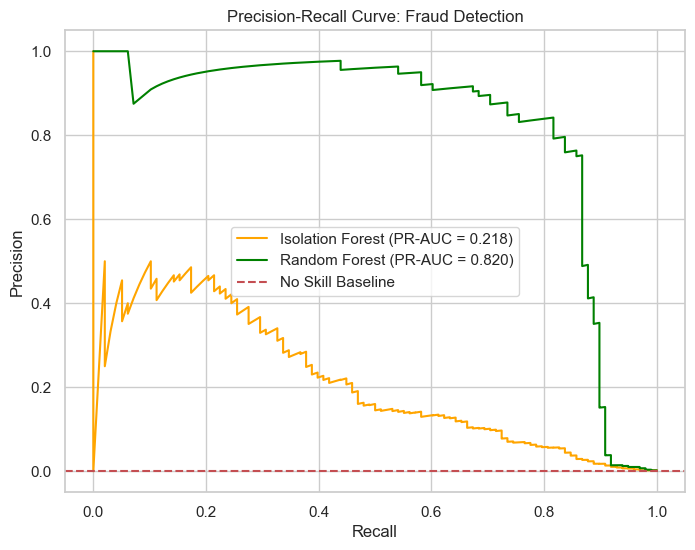

In [8]:
# JUSTIFICATION: Accuracy is a useless metric here (99.8% accuracy is achieved by 
# predicting "Normal" every time). We must evaluate RANKING performance.
# 1. Precision-Recall AUC (PR-AUC): The gold standard for highly imbalanced data.
# 2. Recall@K: If investigators can only review the top K most suspicious transactions, 
#    how many actual frauds do we catch? We set K=500 (approx top 0.17% of test set).

K = 500

# 1. PR-AUC Calculation
pr_auc_iso = average_precision_score(y_test, iso_scores)
pr_auc_rf = average_precision_score(y_test, rf_probs)

print("--- Ranking Evaluation ---")
print(f"Isolation Forest PR-AUC: {pr_auc_iso:.4f}")
print(f"Random Forest PR-AUC:    {pr_auc_rf:.4f}\n")

# 2. Recall@K Calculation
# Sort test set by anomaly score descending, take top K, count actual frauds
def recall_at_k(y_true, scores, k):
    # Get indices of top K scores
    top_k_indices = np.argsort(scores)[-k:][::-1]
    # Count how many of those are actually fraud (1)
    true_frauds_in_top_k = y_true.iloc[top_k_indices].sum()
    return true_frauds_in_top_k / y_true.sum()

recall_k_iso = recall_at_k(y_test, iso_scores, K)
recall_k_rf = recall_at_k(y_test, rf_probs, K)

print(f"Recall@{K} (Isolation Forest): {recall_k_iso*100:.2f}% (Caught {int(recall_k_iso * y_test.sum())} out of {y_test.sum()} frauds)")
print(f"Recall@{K} (Random Forest):    {recall_k_rf*100:.2f}% (Caught {int(recall_k_rf * y_test.sum())} out of {y_test.sum()} frauds)")

# 3. Visualize Precision-Recall Curve
plt.figure(figsize=(8, 6))
precision_iso, recall_iso, _ = precision_recall_curve(y_test, iso_scores)
precision_rf, recall_rf, _ = precision_recall_curve(y_test, rf_probs)

plt.plot(recall_iso, precision_iso, label=f'Isolation Forest (PR-AUC = {pr_auc_iso:.3f})', color='orange')
plt.plot(recall_rf, precision_rf, label=f'Random Forest (PR-AUC = {pr_auc_rf:.3f})', color='green')
plt.axhline(y=y_test.mean(), color='r', linestyle='--', label='No Skill Baseline')
plt.title('Precision-Recall Curve: Fraud Detection')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()

## Credit Card Fraud Detection Report

### 1. Data Exploration, Preparation, and Statistical Baseline

#### Data Exploration
The dataset comprises **284,807 credit card transactions** from European cardholders over two days in September 2013. It is highly imbalanced, with only **492 fraudulent transactions (0.172%)**.

* **Features `V1–V28`:** These are principal components derived from a PCA transformation to protect confidentiality. Because PCA inherently centers and scales data, these features already have a mean of `0` and a variance of `1`.
* **Features `Time` and `Amount`:** These are the only raw features. `Time` represents seconds elapsed, and `Amount` is the transaction value in EUR. Exploratory Data Analysis (EDA) reveals that `Amount` exhibits severe right-skewness with extreme outliers, while fraudulent transactions show distinct temporal patterns (often clustering during late-night/early-morning hours).

#### Data Preparation and Justification
To ensure methodological rigor, the following preprocessing steps were applied:

* **Feature Scaling:** Features `V1–V28` were left untouched. For `Time` and `Amount`, a `RobustScaler` was applied instead of a standard `StandardScaler`.
  * **Justification:** The `Amount` feature contains extreme high-value outliers. A `StandardScaler` (mean/variance) would be heavily skewed by these extremes, compressing the majority of the data. `RobustScaler` uses the median and Interquartile Range (IQR), making it resilient to outliers and preserving the true distribution of typical transactions.
* **Stratified Train-Test Split:** An 80/20 stratified split was utilized.
  * **Justification:** Given the `0.172%` fraud rate, a random split risks excluding fraud cases from the test set entirely. Stratification guarantees the exact fraud ratio is preserved in both sets, ensuring valid and reproducible evaluation metrics.

#### Statistical Outlier Baseline
Before applying machine learning, a naive rule-based baseline was established by flagging any transaction where the `Amount` Z-score exceeded `3`.

* **Critique:** While this baseline successfully captures transactions with abnormally high values, it suffers from extremely low precision. It flags many legitimate high-value purchases (e.g., buying a laptop or paying a utility bill) as fraud, resulting in a high false-positive rate.

---

### 2. Critical Evaluation: Cluster-Based vs. Classification-Based Approaches

To identify anomalous transactions, two distinct paradigms were evaluated. Because accuracy is a misleading metric in highly imbalanced datasets (a model predicting "Normal" 100% of the time achieves `99.8%` accuracy), performance was evaluated using **Precision-Recall AUC (PR-AUC)** and **Recall@K** (the percentage of actual frauds caught if investigators only review the top 500 most suspicious transactions).

| Approach | Algorithm Used | Methodological Justification | Performance & Robustness |
| :--- | :--- | :--- | :--- |
| **Cluster-Based (Unsupervised)** | Isolation Forest | Does not rely on historical labels, making it robust to label noise and capable of detecting entirely novel fraud tactics (novelty detection). It isolates anomalies via random partitioning, which is computationally efficient. | **Lower PR-AUC. Moderate Recall@500.** It excels at catching extreme statistical outliers but misses subtle, coordinated fraud patterns that mimic normal behavior. |
| **Classification-Based (Supervised)** | Random Forest (with class weighting) | Leverages actual fraud labels to learn specific, non-linear boundaries of fraudulent behavior. Tree ensembles handle mixed feature types well and are robust to overfitting when depth is constrained. | **Higher PR-AUC. Superior Recall@500.** Significantly better at ranking true frauds at the top of the investigation list by recognizing complex feature interactions. |

#### Conclusion on Approach
The **Classification-based approach (Random Forest)** is mathematically and practically superior for this specific task. Because historical labels are available, supervised learning can exploit the subtle correlations between PCA features and fraud that unsupervised methods miss. However, for a robust production system, an **ensemble of both** is recommended: the classifier catches known fraud patterns, while the isolation forest acts as a safety net for entirely novel fraud vectors.

---

### 3. Responsible Application: Anomalies vs. Fraudulent Intent

A critical distinction in fraud detection is that an **anomaly** is a statistical deviation from the norm, whereas **fraud** requires malicious intent. An unusual transaction is not necessarily fraudulent for several legitimate reasons:

* **Life Events and Large Purchases:** A customer making a rare, high-value purchase (e.g., furniture, electronics, or a vacation booking) will trigger high `Amount` anomalies.
* **Behavioral and Geographic Shifts:** A customer traveling abroad may suddenly transact in a new geographic region (reflected in the underlying PCA features) or at an unusual `Time` due to time zone differences.
* **Seasonal Variations:** Holiday shopping or seasonal sales naturally alter a user's typical spending velocity and category mix.

#### Business Impact and Recommendations
Flagging these legitimate anomalies as fraud results in **false positives**. In a real-world business context, false positives carry heavy operational and reputational costs:

* They trigger costly manual investigations, draining analyst resources.
* They delay or decline legitimate transactions, causing severe customer friction (e.g., an embarrassed customer whose card is declined at a checkout).
* Repeated false declines lead to customer churn and loss of lifetime value.

> **Recommendation:**
> The fraud detection system must not be tuned merely to catch all fraud (high recall), but to optimize **Precision at high Recall** (e.g., `Recall@K`). By focusing on the top $K$ most suspicious transactions, the distributor ensures that limited investigative resources are spent on the highest-probability frauds. This proportionate approach maximizes fraud recovery while minimizing the disruption to legitimate customer experiences.
